# Raster Scanning Stimulation

In this tutorial we'll see how to
 - set up raster scanning 2P optogenetic stimulation using a `Scope`
 - configure pulse train parameters for the scanning light
 - simulate sequential neuron activation and visualize the results

## Preamble

In [1]:
import brian2.only as b2
from brian2 import np
import cleo
from cleo import opto, imaging, light
import matplotlib.pyplot as plt

# slightly faster than numpy in this case
b2.prefs.codegen.target = "cython"

# for reproducibility
rng = np.random.default_rng(18010630)
cleo.utilities.set_seed(18501224)

cleo.utilities.style_plots_for_docs()

## Brian network setup

We'll use simple LIF neurons that respond to photostimulation via `Iopto`.

In [2]:
ng = b2.NeuronGroup(
    200,
    """dv/dt = (-(v - E_L) + Rm*Iopto) / tau_m : volt
    Iopto : amp""",
    threshold="v > -50*mV",
    reset="v=E_L",
    namespace={
        "tau_m": 20 * b2.ms,
        "Rm": 500 * b2.Mohm,
        "E_L": -70 * b2.mV,
    },
)
ng.v = -70 * b2.mV
cleo.coords.assign_coords_rand_rect_prism(ng, [-0.2, 0.2], [-0.2, 0.2], [0, 0.4])
sim = cleo.CLSimulator(b2.Network(ng))

## Microscope configuration

By default a scope selects neurons based on focus depth and assigns them a signal-to-noise ratio (SNR) based on soma size.
(Larger cells' SNR decays more slowly with distance from the focal plane.)
`focus_depth` and `soma_radius` are taken from scope parameters but can be overridden on injection.

We'll use GCaMP6f as our indicator and leave the default parameters, though those can be changed in the function call {func}`~cleo.imaging.gcamp6f`.

In [3]:
scope = imaging.Scope(
    focus_depth=100 * b2.um,
    img_width=500 * b2.um,
    sensor=imaging.gcamp6f(),
)
sim.inject(scope, ng)

CLSimulator(io_processor=None, devices={Scope(name='Scope', save_history=True, sensor=GECI(name='GCaMP6f', save_history=True, model='\n            dCa/dt = -gamma * (Ca - Ca_rest) / (1 + kappa_S + kappa_B) : mmolar (clock-driven)\n            kappa_B = B_T * K_d / (Ca + K_d)**2 : 1\n\n            CaB_active = Ca_rest + b : mmolar  # add tiny bit to avoid /0\n            db/dt = beta : mmolar (clock-driven)\n            lam = 1/tau_off + 1/tau_on : 1/second\n            kap = 1/tau_off : 1/second\n            dbeta/dt = (                    # should be M/s/s\n                A * (lam - kap) * (Ca - Ca_rest)  # M/s/s\n                - (kap + lam) * beta        # M/s/s\n                - kap * lam * b    # M/s/s\n            ) : mmolar/second (clock-driven)\n            \nexc_factor = 1 : 1\n\n            dFF_baseline = 1 / (1 + (K_d / Ca_rest) ** n_H) : 1\n            dFF = exc_factor * rho_rel * dFF_max  * (\n                1 / (1 + (K_d / CaB_active) ** n_H)\n                - dFF_ba

## Opsin configuration

We inject an opsin to make the neurons light-sensitive. Here we use ChRmine, a highly sensitive red-shifted opsin well-suited for 2P stimulation due to its large photocurrent response at low light intensities.

In [4]:
opsin = opto.chrmine_4s()
sim.inject(opsin, ng)

WARNING    Removing unsupported flag '-march=native' from compiler flags. [brian2.codegen.cpp_prefs]


CLSimulator(io_processor=None, devices={BansalFourStateOpsin(name='ChRmine', save_history=True, on_pre='', spectrum=[(390, 0.37), (410, 0.55), (430, 0.72), (450, 0.85), (470, 0.93), (491, 0.99), (510, 1), (531, 0.98), (551, 0.94), (570, 0.86), (591, 0.7), (610, 0.48), (630, 0.26), (650, 0.1)], extrapolate=False, required_vars=[('Iopto', amp), ('v', volt)], Gd1=20. * hertz, Gd2=13. * hertz, Gr0=0.59 * hertz, g0=110. * nsiemens, phim=2.1e+21 * (second ** -1) / (meter ** 2), k1=200. * hertz, k2=10. * hertz, Gf0=2.7 * hertz, Gb0=0.5 * hertz, kf=1. * hertz, kb=0. * hertz, gamma=0.05, p=0.8, q=1, E=5.64 * mvolt, model='\n        dC1/dt = Gd1*O1 + Gr0*C2 - Ga1*C1 : 1 (clock-driven)\n        dO1/dt = Ga1*C1 + Gb*O2 - (Gd1+Gf)*O1 : 1 (clock-driven)\n        dO2/dt = Ga2*C2 + Gf*O1 - (Gd2+Gb)*O2 : 1 (clock-driven)\n        C2 = 1 - C1 - O1 - O2 : 1\n\n        Theta = int(phi_pre > 0*phi_pre) : 1\n        Hp = Theta * phi_pre**p/(phi_pre**p + phim**p) : 1\n        Ga1 = k1*Hp : hertz\n        Ga2

## Raster scanning light configuration

Raster scanning works by sweeping a focused 2P laser beam across target neurons one at a time in rapid succession. Each neuron receives a brief pulse of light during its designated time slot in the scan cycle. The pulse width is computed automatically from the scope's `soma_radius` and `img_width`. Larger neurons relative to the imaging field means longer pulses per neuron.

We create the imaging light via the scope, which sets the scanning parameters automatically:

WARNING    /Users/randismaael/Documents/cleo/cleo/light/light_dependence.py:133: UserWarning: λ = 1040.0 nm is outside the range of the action spectrum data for ChRmine and extrapolate=False. Assuming ε = 0.
  warnings.warn(
 [py.warnings]


(<Figure size 640x480 with 1 Axes>,
 <Axes3D: xlabel='x (um)', ylabel='y (um)', zlabel='z (um)'>)

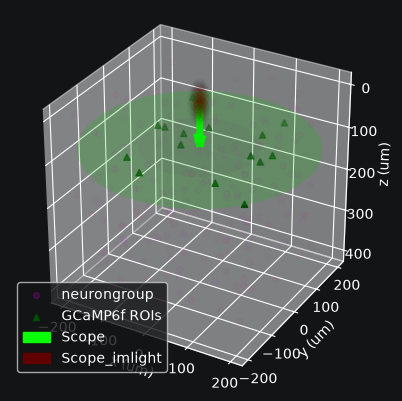

In [5]:
scope.inject_imaging_light_for_targets(
    scan_freq=30,
    wavelength=1040 * b2.nmeter,
)

cleo.viz.plot(ng, colors=["#c500cc"], sim=sim)